# **Calibrate Tx system**

- Calibrated params: ``[x y z roll pitch yaw k1 k2 k3] x 3``
- Calibration algorithm: `least_squares` from scipy

Workflow:
1. Section 1: initial setup
2. Section 2: upload data file, choose correct file path and load data
3. Section 3:
- Choose Tx to calibrate
- Run 3.1 to calibrate, 3.2 to store individual results
- Repeat for all Tx
4. Section 4: inverse solver for all Tx calibrations using stored results
5. Section 5: extract results for reports

# **1. Import & Define Target Functions**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import time

# --- Helper Rotation Functions ---
def rotx(deg):
    c, s = np.cos(np.radians(deg)), np.sin(np.radians(deg))
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def roty(deg):
    c, s = np.cos(np.radians(deg)), np.sin(np.radians(deg))
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def rotz(deg):
    c, s = np.cos(np.radians(deg)), np.sin(np.radians(deg))
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

# --- CODE 1: Forward Model ---
def forwardModel_dio(params, sys_dict, Rx):
    # params = [x, y, z, roll, pitch, yaw]
    x, y, z, roll, pitch, yaw = params

    RCE = rotz(yaw) @ roty(pitch) @ rotx(roll)
    if Rx == 1:
        RXk = RCE @ np.array([1, 0, 0])
    elif Rx == 2:
        RXk = RCE @ np.array([0, 0, 1])
    elif Rx == 3:
        RXk = RCE @ np.array([0, 1, 0])

    mu0 = 4 * np.pi * 1e-7
    Atx = np.pi * sys_dict['R']**2
    nCoils = sys_dict['TX_positions'].shape[1]
    EMF = np.zeros(nCoils)

    for i in range(nCoils):
        x_tx, y_tx, z_tx, roll_tx, pitch_tx, yaw_tx = sys_dict['TX_positions'][:, i]

        r_vec = np.array([x, y, z]) - np.array([x_tx, y_tx, z_tx])
        r = np.linalg.norm(r_vec)
        r_hat = r_vec / r
        m_local = sys_dict['Ntx'] * sys_dict['I'][i]

        Rtx = rotz(yaw_tx) @ roty(pitch_tx) @ rotx(roll_tx)
        D = Rtx @ np.array([0, 0, 1])
        m_vec = m_local * Atx * D

        B = (mu0 / (4 * np.pi * r**3)) * (3 * np.dot(m_vec, r_hat) * r_hat - m_vec)
        EMF[i] = 2 * np.pi * sys_dict['f'][i] * np.abs(np.dot(B, RXk))

    return EMF

# --- CODE 2: Calibration Objective Function ---
def calib_Tx_single(x_params, d, sys_dict, Tx_id, nRx):
    # x_params = [x y z roll pitch yaw K1 K2 K3]
    tx_param = x_params[0:6]
    K = x_params[6:6+nRx]

    sys_local = sys_dict.copy()
    sys_local['TX_positions'] = sys_dict['TX_positions'].copy()
    sys_local['TX_positions'][:, Tx_id] = tx_param

    N = d.shape[0]
    F = np.zeros(N * nRx)

    for j in range(nRx):
        for i in range(N):
            # params = [x_m, y_m, z_m, roll, pitch, yaw]
            params = [d[i, 9]/1000, d[i, 10]/1000, d[i, 11]/1000, d[i, 12], d[i, 13], d[i, 14]]

            emf_model_all = forwardModel_dio(params, sys_local, j+1) # j+1 because Rx is 1,2,3
            emf_model = K[j] * emf_model_all[Tx_id]
            emf_meas = d[i, Tx_id + 3*j]

            F[j*N + i] = emf_model - emf_meas
    return F

# **2. Load Data**

Remember to pre-upload data file.
Data format:
``3_Rx1 3_Rx2 3_Rx3 3_Pos 3_Ori``

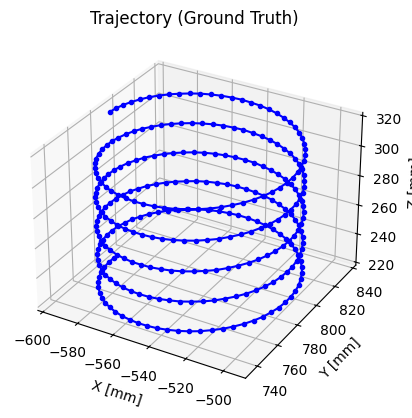

In [ ]:
# ===== LOAD DATA =====
# Assuming file is uploaded directly to Colab workspace
file_path = '/content/data_cylnorot.csv'
data1 = pd.read_csv(file_path, header=None).values

# In Python, arrays are 0-indexed. MATLAB columns 1-15 become 0-14.
X_emf = data1[:, 0:9]
x, y, z = data1[:, 9], data1[:, 10], data1[:, 11]
roll, pitch, yaw = data1[:, 12], data1[:, 13], data1[:, 14]
Y_pose = data1[:, 9:15]
d = np.hstack((X_emf, Y_pose))

# ===== VẼ QUỸ ĐẠO BAN ĐẦU =====
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, 'b.-')
ax.set_xlabel('X [mm]')
ax.set_ylabel('Y [mm]')
ax.set_zlabel('Z [mm]')
ax.set_title('Trajectory (Ground Truth)')
plt.show()

# ===== SYSTEM CONFIG =====
nTx, nRx = 3, 3
sys_pre = {
    'Ntx': 300, 'Nrx': 300, 'R': 0.06,
    'AK': np.pi * (2.6e-3)**2,
    'I': np.ones(nTx),
    'f': [5053, 6911, 5932],
    'TX_positions': np.zeros((6, nTx))
}

# 11/9/26 configuration
sys_pre['TX_positions'][:, 0] = [-0.6, 0.6, 0.15824, 15, 0, 0]
sys_pre['TX_positions'][:, 1] = [-0.6, 0.6, 0.15471, 0, -15, -30]
sys_pre['TX_positions'][:, 2] = [-0.6, 0.6, 0.15470, 0, 15, 30]

k_local = np.array([sys_pre['Nrx'] * sys_pre['AK']] * nRx)

sys_calib = sys_pre.copy()
sys_post  = sys_pre.copy()
K_post = np.zeros((nRx, nTx))

# **3. Optimization**

## **3.1 Individual Tx calibration**

In [ ]:
# Choose TX
Tx_id = 3

Tx_id -= 1 # index matching

# ===== INITIAL GUESS =====
x0 = np.concatenate((sys_pre['TX_positions'][:, Tx_id], k_local))

lb = [-0.6,  0.6, 0.0, -180, -180, -180,  0,  0,  0]
ub = [-0.3,  0.9, 0.5,  180,  180,  180, 60, 70, 60]

print("Starting Calibration Optimization. This might take a few moments...")

# scipy's least_squares replaces lsqnonlin. 'trf' is Trust Region Reflective
res = least_squares(
    lambda x: calib_Tx_single(x, d, sys_pre, Tx_id, nRx),
    x0,
    bounds=(lb, ub),
    method='trf',
    verbose=2 # Displays iterations similar to 'Display':'iter'
)

x_opt = res.x
print('\n=== RESULT ===')
print(','.join([f"{v:.5f}" for v in x_opt]))

# Update System Post-Calib for testing
sys_calib['TX_positions'][:, Tx_id] = x_opt[0:6]
K_opt = x_opt[6:6+nRx]

# =========================================================
# 🔴 Compute EMF Models (Pre & Post) and 🟣 Plot Errors
# =========================================================

N = d.shape[0]

# --- 1. Compute Pre-Calib Model and Extract Measured EMF ---
emf_model_pre = np.zeros((N, nRx))
emf_meas = np.zeros((N, nRx))
emf_model_post = np.zeros((N, nRx))

print("\nComputing pre and post calibration errors...")

for j in range(nRx):
    # Extract measured EMF for this specific Tx and Rx
    # MATLAB: d(:, Tx_id + 3*(j-1)). Python: d[:, Tx_id + 3*j]
    emf_meas[:, j] = d[:, Tx_id + 3*j]

    for i in range(N):
        # Unpack pose [x, y, z, roll, pitch, yaw]
        params = [d[i, 9]/1000, d[i, 10]/1000, d[i, 11]/1000, d[i, 12], d[i, 13], d[i, 14]]

        # Pre-calib calculation
        emf_all_pre = forwardModel_dio(params, sys_pre, j+1)
        emf_model_pre[i, j] = emf_all_pre[Tx_id]

        # Post-calib calculation
        emf_all_post = forwardModel_dio(params, sys_calib, j+1)
        emf_model_post[i, j] = K_opt[j] * emf_all_post[Tx_id]

# --- 2. Plot Error Comparison ---
for j in range(nRx):
    err_pre = np.abs(emf_meas[:, j] - emf_model_pre[:, j])
    err_post = np.abs(emf_meas[:, j] - emf_model_post[:, j])

    plt.figure(figsize=(8, 4))
    plt.plot(err_pre, 'k--', label='Error Pre')
    plt.plot(err_post, 'r-', label='Error Post')

    plt.title(f'Error Comparison - Tx {Tx_id+1} - Rx {j+1}')
    plt.xlabel('Sample Index')
    plt.ylabel('Absolute Error (mV)')
    plt.legend()
    plt.grid(True)
    plt.show()

## **3.2 After calibrating for Tx_id**
For running section 4, temporarily update calib results to `sys_post`: (will be lost when runtime is disconnected)

In [ ]:
sys_post['TX_positions'][:, Tx_id] = x_opt[0:6]
K_post[:, Tx_id] = x_opt[6:6+nRx]

np.set_printoptions(formatter={'float': '{:0.5f}'.format})
print(x_opt)

# **4. Inverse Solver**

- Evaluate localization results with new fully calibrated Tx parameters.
- Inverse solver: `least_squares` from scipy

In [ ]:
# --- Inverse Solver Functions ---
def forward_full(pose, sys_dict, Rx, K_vec):
    emf_raw = forwardModel_dio(pose, sys_dict, Rx)
    return K_vec * emf_raw

def build_residual(p, sys_dict, emf_j, nTx, nRx, K_vec):
    res = np.zeros(nTx * nRx)
    for i in range(nRx):
        emf_i = forward_full(p, sys_dict, i+1, K_vec[i, :])
        # MATLAB index: (i-1)*nTx + (1:nTx). Python: i*nTx to (i+1)*nTx
        idx = slice(i*nTx, (i+1)*nTx)
        res[idx] = emf_i - emf_j[idx]
    return res

# --- 1. Prepare system arrays ---
N = len(x)
traj_x, traj_y, traj_z = x/1000, y/1000, z/1000
EMF_meas = X_emf.T # Shape: 9 x N

K_pre = np.full((nRx, nTx), sys_pre['Nrx'] * sys_pre['AK'])

# --- 2. Optimization Loop (Pre & Post) ---
lb_inv = [np.min(traj_x)-0.1, np.min(traj_y)-0.1, np.min(traj_z)-0.1, np.min(roll)-10, np.min(pitch)-10, np.min(yaw)-10]
ub_inv = [np.max(traj_x)+0.1, np.max(traj_y)+0.1, np.max(traj_z)+0.1, np.max(roll)+10, np.max(pitch)+10, np.max(yaw)+10]

x_pre, y_pre, z_pre = np.zeros(N), np.zeros(N), np.zeros(N)
x_post, y_post, z_post = np.zeros(N), np.zeros(N), np.zeros(N)
compute_times = np.zeros(N)

print(f"Running inverse solver for {N} poses (Pre and Post Calibration)...")
for j in range(N):
    emf_j = EMF_meas[:, j]
    p0 = [traj_x[j]+0.0001, traj_y[j]+0.0001, traj_z[j]+0.0001, roll[j], pitch[j], yaw[j]]

    # --- PRE-CALIB SOLVE ---
    res_pre = least_squares(
        lambda p: build_residual(p, sys_pre, emf_j, nTx, nRx, K_pre),
        p0, bounds=(lb_inv, ub_inv), method='trf'
    )
    x_pre[j], y_pre[j], z_pre[j] = res_pre.x[0:3]

    # --- POST-CALIB SOLVE ---
    start_t = time.time()
    res_post = least_squares(
        lambda p: build_residual(p, sys_post, emf_j, nTx, nRx, K_post),
        p0, bounds=(lb_inv, ub_inv), method='trf'
    )
    compute_times[j] = time.time() - start_t
    x_post[j], y_post[j], z_post[j] = res_post.x[0:3]

# --- 3. Print Results & RMSE Errors ---
avg_time_ms = np.mean(compute_times) * 1000
fps = 1.0 / np.mean(compute_times)
print('\n===== COMPUTATION TIME =====')
print(f" Avg Inference Time: {avg_time_ms:.4f} ms / pose")
print(f" Equivalent Update Rate: {fps:.2f} Hz (FPS)\n")

err_x_pre, err_y_pre, err_z_pre = (x_pre - traj_x)*1e3, (y_pre - traj_y)*1e3, (z_pre - traj_z)*1e3
err_x_post, err_y_post, err_z_post = (x_post - traj_x)*1e3, (y_post - traj_y)*1e3, (z_post - traj_z)*1e3

err_mag_pre = np.sqrt(err_x_pre**2 + err_y_pre**2 + err_z_pre**2)
err_mag_post = np.sqrt(err_x_post**2 + err_y_post**2 + err_z_post**2)

rmse_pre = np.sqrt(np.mean(err_mag_pre**2)/3)
rmse_post = np.sqrt(np.mean(err_mag_post**2)/3)

print(f'RMSE Pre-Calib  = {rmse_pre:.2f} mm')
print(f'RMSE Post-Calib = {rmse_post:.2f} mm')

# --- 4. Plot Trajectory ---
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(traj_x*1000, traj_y*1000, traj_z*1000, 'k-', linewidth=3, label='Ground Truth Path')
ax.plot(x_post*1000, y_post*1000, z_post*1000, 'r-', linewidth=3, label='Estimated path (Post-Calib)')
ax.set_xlabel('X (mm)'); ax.set_ylabel('Y (mm)'); ax.set_zlabel('Z (mm)')
ax.legend()
plt.title('3D Trajectory Comparison')
plt.show()

# --- 5. Generate Full EMF Data arrays for Plotting ---
EMF_pre_full = np.zeros((nTx * nRx, N))
EMF_post_full = np.zeros((nTx * nRx, N))

for j in range(N):
    pose_truth = [traj_x[j], traj_y[j], traj_z[j], roll[j], pitch[j], yaw[j]]
    for i in range(nRx):
        idx = slice(i*nTx, (i+1)*nTx)
        EMF_pre_full[idx, j] = forward_full(pose_truth, sys_pre, i+1, K_pre[i, :])
        EMF_post_full[idx, j] = forward_full(pose_truth, sys_post, i+1, K_post[i, :])

# --- 6. Plot Dense EMF Grid Comparison (MATLAB tiledlayout equivalent) ---
fig, axes = plt.subplots(nTx, nRx, figsize=(15, 10), sharex=True)
fig.suptitle('EMF Pre-Post Comparison', fontsize=16, fontweight='bold')

for j in range(nTx):       # Iterate over Transmitters
    for i in range(nRx):   # Iterate over Receivers
        ax = axes[j, i]
        row_idx = i * nTx + j

        # Plotting the three lines
        ax.plot(EMF_meas[row_idx, :], 'k', linewidth=1.2, label='Measured')
        ax.plot(EMF_pre_full[row_idx, :], 'b--', linewidth=1.0, label='Pre-Calib')
        ax.plot(EMF_post_full[row_idx, :], 'r', linewidth=1.2, label='Post-Calib')

        ax.set_title(f'Tx {j+1} - Rx {i+1}', fontsize=10, fontweight='bold')
        ax.grid(True)

        # Only add axis labels to outer plots
        if j == nTx - 1:
            ax.set_xlabel('Sample Index')
        if i == 0:
            ax.set_ylabel('EMF')

# Place a single legend at the bottom center of the figure
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, 0.02))

# Adjust layout to make room for the bottom legend
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

## **5. Extract calibration results**

In [ ]:
print('\n===== COMPUTATION TIME =====')
print(f"Avg Inference Time: {avg_time_ms:.4f} ms / pose")
print(f"Equivalent Update Rate: {fps:.4f} Hz (FPS)\n")
print('\n===== ERROR COMPARISON =====')
print(f'RMSE Pre-Calib  = {rmse_pre:.4f} mm')
print(f'RMSE Post-Calib = {rmse_post:.4f} mm\n')

print('\n===== CSV CALIB RESULS =====')
print('x,y,z,roll,pitch,yaw,k1,k2,k3')
x_results = np.zeros((nTx, 9))

for i in range(nTx):
  x_results[i,:6] = sys_post['TX_positions'][:6,i]
  x_results[i,6:] = K_post[:,i]
  print(",".join(f"{x:.4f}" for x in x_results[i,:]))